Generalized Glivenko-Cantelli theorem

In this script I verify the extended Glivenko-Cantelli theorem

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

from hfp_tools import exp_decay_probs, ens, hfp_cdf

1. Generate gamma scenarios

In [2]:
# ---------------------------------------------------------------------------
# 1. Generate gamma scenarios  eps_t ~ Gamma(k, theta), i.i.d.
# ---------------------------------------------------------------------------
# shape
k = 1
# scale
theta = 2
# number of observations
t_bar = 2500
rng = np.random.default_rng(42)

dist = gamma(k, scale=theta)
eps = dist.rvs(size=t_bar, random_state=rng)

2. Compute time exponential decay probabilities

In [3]:
# ---------------------------------------------------------------------------
# 2. Time exponential-decay probabilities (eq. 17.6)
# ---------------------------------------------------------------------------
t_star = t_bar          # target time: the most recent observation
tau_hl = t_star / 2     # half-life
p = exp_decay_probs(t_bar, tau_hl, t_star)

3. Compute effective number of scenarios

In [4]:
# ---------------------------------------------------------------------------
# 3. Effective number of scenarios (eq. 17.21)
# ---------------------------------------------------------------------------
print(f"Effective number of scenarios: {ens(p):.0f} out of {t_bar}")

Effective number of scenarios: 2316 out of 2500


4. Compute HFP and true gamma cdf

In [6]:
# ---------------------------------------------------------------------------
# 4. HFP cdf vs true gamma cdf (eq. 17.29)
# ---------------------------------------------------------------------------
x_grid = np.linspace(0, eps.max(), 1000)
cdf_hfp = hfp_cdf(x_grid, eps, p)
cdf_true = dist.cdf(x_grid)

5. Compute true gamma pdf

Text(0.5, 0, 't')

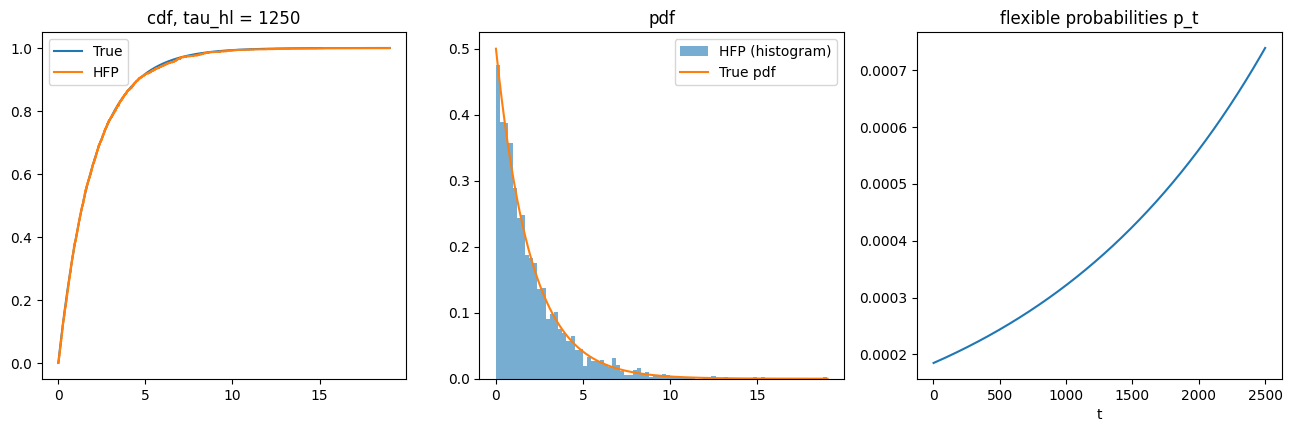

In [12]:
# ---------------------------------------------------------------------------
# 5. HFP pdf (weighted histogram) vs true gamma pdf (eq. 17.28)
# ---------------------------------------------------------------------------
pdf_true = dist.pdf(x_grid)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(x_grid, cdf_true, label="True")
ax[0].step(x_grid, cdf_hfp, where="post", label="HFP")
ax[0].set_title(f"cdf, tau_hl = {tau_hl:.0f}")
ax[0].legend()

ax[1].hist(eps, bins=80, weights=p, density=True, alpha=0.6, label="HFP (histogram)")
ax[1].plot(x_grid, pdf_true, label="True pdf")
ax[1].set_title("pdf")
ax[1].legend()

ax[2].plot(np.arange(1, t_bar + 1), p)
ax[2].set_title("flexible probabilities p_t")
ax[2].set_xlabel("t")

6. Extra: Shrink the half-life -> ens drops -> showing the fit gets worse

In [13]:
# ---------------------------------------------------------------------------
# 6. Extra: shrink the half-life -> ens drops -> the fit gets worse
# ---------------------------------------------------------------------------
# sup|F_HFP - F| is evaluated just before and at every jump of the staircase,
# which is where the largest gap can sit.
order = np.argsort(eps)
eps_sorted = eps[order]
F_true_at_jumps = dist.cdf(eps_sorted)

print(f"\n{'tau_hl':>8} | {'ens(p)':>8} | {'sup|F_HFP - F|':>15}")
for tau in [10, 50, 250, 1250, 10_000, np.inf]:
    p_tau = np.full(t_bar, 1 / t_bar) if np.isinf(tau) else exp_decay_probs(t_bar, tau)
    cum = np.cumsum(p_tau[order])
    sup = max(np.max(np.abs(cum - F_true_at_jumps)),
              np.max(np.abs(np.concatenate(([0.0], cum[:-1])) - F_true_at_jumps)))
    print(f"{tau:>8} | {ens(p_tau):>8.0f} | {sup:>15.4f}")

fig.tight_layout()
plt.show()


  tau_hl |   ens(p) |  sup|F_HFP - F|
      10 |       39 |          0.2127
      50 |      196 |          0.0668
     250 |      973 |          0.0179
    1250 |     2316 |          0.0101
   10000 |     2497 |          0.0084
     inf |     2500 |          0.0085
